# Medium world — Long-budget curriculum
Run all cells to train. Set `LR_POLICY` to `"constant"` or `"cosine"`; each policy saves to its own output folder.

In [1]:
from pathlib import Path
SEEDS = [42, 43, 44, 45, 46]
SCHEDULES = ("mixed", "staged", "staged_rehearsal", "reverse")
MAIN_EPOCHS, COMMON_EPOCHS, REHEARSAL_EPOCHS = 36, 9, 3
BATCH_SIZE, EVAL_EVERY = 50, 100
INITIAL_LR, FINAL_LR = 1e-4, 1e-5
LR_POLICY = "constant"  # "constant" or "cosine"
WEIGHT_DECAY = 0.0
MODEL_DIM, PATCH_SIZE = 48, 4
AUGMENT = True
SAVE_CHECKPOINTS = False
DEVICE = "cuda"
DATA_REL = Path("outputs/medium_world/dataset")
OUT_REL = Path("outputs/medium_world/experiments") / f"long_budget_{LR_POLICY}"

In [2]:
import sys, json, math, hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "src/medium_visual_world/learning.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.medium_visual_world.learning import (
    TASKS, MediumDataset, AttributeBindingViT, augment_images, set_seed, environment
)
from src.medium_visual_world.curriculum import make_blocks

device = torch.device(DEVICE)
DATA_DIR, OUT_DIR = PROJECT_ROOT / DATA_REL, PROJECT_ROOT / OUT_REL
torch.set_num_threads(min(4, torch.get_num_threads()))
hashes = {name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()
          for name in ("train.jsonl", "id_dev.jsonl", "ood_dev.jsonl")}
train = MediumDataset(DATA_DIR / "train.jsonl")
dev = MediumDataset(DATA_DIR / "id_dev.jsonl")
ood = MediumDataset(DATA_DIR / "ood_dev.jsonl")
print(f"{device} | LR: {LR_POLICY} | {len(train)} train questions | {len(train) * (MAIN_EPOCHS + COMMON_EPOCHS) // BATCH_SIZE:,} updates/run")

cuda | LR: constant | 10000 train questions | 9,000 updates/run


In [3]:
def learning_rate(step, total_steps):
    if LR_POLICY == "constant":
        return INITIAL_LR
    progress = (step - 1) / max(total_steps - 1, 1)
    return FINAL_LR + (INITIAL_LR - FINAL_LR) * (1 + math.cos(math.pi * progress)) / 2

In [4]:
@torch.inference_mode()
def evaluate_here(model, dataset, device, batch_size, limit=None, constant_image=False):
    model.eval()
    n = min(len(dataset), limit) if limit is not None else len(dataset)
    hits, total_loss = 0, 0.0
    counts, correct_by_task = Counter(), Counter()
    for start in range(0, n, batch_size):
        ids = list(range(start, min(start + batch_size, n)))
        x, q, y = dataset.batch(ids, device, constant_image)
        logits = model(x, q)
        total_loss += nn.functional.cross_entropy(logits, y, reduction="sum").item()
        correct = (logits.argmax(1) == y).tolist()
        for i, is_correct in zip(ids, correct):
            task = dataset.tasks[i]
            counts[task] += 1
            correct_by_task[task] += int(is_correct)
            hits += int(is_correct)
    return {"n": n, "accuracy": hits / n, "loss": total_loss / n,
            "by_template": {task: correct_by_task[task] / counts[task]
                             for task in counts if counts[task]}}

def curve_area(history, task="pair"):
    points = sorted({entry["step"]: entry["id_dev"]["by_template"][task]
                     for entry in history}.items())
    width = points[-1][0]
    return sum((b-a) * (x+y) / 2
               for (a, x), (b, y) in zip(points[:-1], points[1:])) / width

def run_one(schedule, seed, train, dev, ood):
    set_seed(seed)
    model = AttributeBindingViT(dim=MODEL_DIM, patch_size=PATCH_SIZE).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=INITIAL_LR, weight_decay=WEIGHT_DECAY)
    blocks, plan = make_blocks(train.rows, schedule, MAIN_EPOCHS, COMMON_EPOCHS, seed, REHEARSAL_EPOCHS)
    steps = sum(len(ids) // BATCH_SIZE for _, ids in blocks)
    history, running_loss, batches, step = [], 0.0, 0, 0
    best_loss, best_step = float("inf"), 0

    def evaluate_step(phase):
        nonlocal running_loss, batches, best_loss, best_step
        id_dev = evaluate_here(model, dev, device, BATCH_SIZE)
        ood_dev = evaluate_here(model, ood, device, BATCH_SIZE)
        history.append({"step": step, "phase": phase,
                        "batch_train_loss": running_loss / batches if batches else None,
                        "lr": optimizer.param_groups[0]["lr"],
                        "id_dev": id_dev, "ood_dev": ood_dev})
        if id_dev["loss"] < best_loss:
            best_loss, best_step = id_dev["loss"], step
            if SAVE_CHECKPOINTS:
                ckpt_dir = OUT_DIR / "checkpoints"
                ckpt_dir.mkdir(parents=True, exist_ok=True)
                torch.save({"model": model.state_dict(), "step": step, "seed": seed,
                            "schedule": schedule, "dim": MODEL_DIM, "patch_size": PATCH_SIZE},
                           ckpt_dir / f"{schedule}_{seed}_best.pt")
        running_loss, batches = 0.0, 0
        pair_acc = id_dev["by_template"].get("pair", float("nan"))
        print(f"{schedule:17} seed={seed} step={step:5} phase={phase:12} "
              f"pair={pair_acc:.3f} overall={id_dev['accuracy']:.3f} "
              f"LR={optimizer.param_groups[0]['lr']:.2g}", flush=True)

    evaluate_step("initial")
    for phase, ids in blocks:
        for start in range(0, len(ids), BATCH_SIZE):
            x, q, y = train.batch(ids[start:start+BATCH_SIZE], device)
            if AUGMENT:
                x = augment_images(x)
            model.train()
            lr = learning_rate(step + 1, steps)
            for group in optimizer.param_groups:
                group["lr"] = lr
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(x, q), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            step += 1
            running_loss += loss.item()
            batches += 1
            if step % EVAL_EVERY == 0:
                evaluate_step(phase)
        if history[-1]["step"] != step:
            evaluate_step(phase)

    final = {"step": step, "phase": "final",
             "id_dev": evaluate_here(model, dev, device, BATCH_SIZE),
             "ood_dev": evaluate_here(model, ood, device, BATCH_SIZE)}
    final["id_dev_constant_image"] = evaluate_here(model, dev, device, BATCH_SIZE, constant_image=True)
    if SAVE_CHECKPOINTS:
        ckpt_dir = OUT_DIR / "checkpoints"
        ckpt_dir.mkdir(parents=True, exist_ok=True)
        torch.save({"model": model.state_dict(), "step": step, "seed": seed,
                    "schedule": schedule, "dim": MODEL_DIM, "patch_size": PATCH_SIZE},
                   ckpt_dir / f"{schedule}_{seed}_final.pt")
    return {"seed": seed, "schedule": schedule, "status": "completed",
            "steps_run": step, "phase_plan": plan,
            "history": history, "final": final,
            "best_id_dev_loss": best_loss, "best_id_dev_step": best_step,
            "id_pair_aulc": curve_area(history)}

## Train
Results are saved after each completed run. Rerunning skips completed seed–schedule pairs.


In [5]:
config = {"schedules": list(SCHEDULES), "main_epochs": MAIN_EPOCHS,
          "common_epochs": COMMON_EPOCHS, "rehearsal_epochs": REHEARSAL_EPOCHS,
          "batch_size": BATCH_SIZE, "eval_every": EVAL_EVERY,
          "lr_policy": LR_POLICY, "initial_lr": INITIAL_LR,
          "final_lr": FINAL_LR if LR_POLICY == "cosine" else INITIAL_LR,
          "weight_decay": WEIGHT_DECAY, "dim": MODEL_DIM,
          "patch_size": PATCH_SIZE, "augment": AUGMENT,
          "total_updates": len(train) * (MAIN_EPOCHS + COMMON_EPOCHS) // BATCH_SIZE}
report_path = OUT_DIR / "schedule_comparison.json"
OUT_DIR.mkdir(parents=True, exist_ok=True)
if report_path.exists():
    report = json.loads(report_path.read_text(encoding="utf-8"))
    if report["config"] != config or report["dataset_hashes"] != hashes:
        raise ValueError("Existing results use different settings or data. Choose a new OUT_REL.")
else:
    report = {"status": "exploratory", "dataset_hashes": hashes,
              "environment": environment(), "config": config, "runs": []}

completed = {(r["seed"], r["schedule"]) for r in report["runs"] if r["status"] == "completed"}
for seed in SEEDS:
    for schedule in SCHEDULES:
        if (seed, schedule) in completed:
            print(f"Skipping completed run: {schedule}, seed={seed}")
            continue
        result = run_one(schedule, seed, train, dev, ood)
        report["runs"].append(result)
        tmp_path = report_path.with_suffix(".json.tmp")
        tmp_path.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
        tmp_path.replace(report_path)
        print(f"Saved {schedule}, seed={seed} → {report_path}", flush=True)
print("All requested runs complete:", report_path)

mixed             seed=42 step=    0 phase=initial      pair=0.500 overall=0.502 LR=0.0001
mixed             seed=42 step=  100 phase=mixed        pair=0.500 overall=0.500 LR=0.0001
mixed             seed=42 step=  200 phase=mixed        pair=0.520 overall=0.527 LR=0.0001
mixed             seed=42 step=  300 phase=mixed        pair=0.543 overall=0.544 LR=0.0001
mixed             seed=42 step=  400 phase=mixed        pair=0.496 overall=0.524 LR=0.0001
mixed             seed=42 step=  500 phase=mixed        pair=0.523 overall=0.548 LR=0.0001
mixed             seed=42 step=  600 phase=mixed        pair=0.520 overall=0.589 LR=0.0001
mixed             seed=42 step=  700 phase=mixed        pair=0.527 overall=0.600 LR=0.0001
mixed             seed=42 step=  800 phase=mixed        pair=0.531 overall=0.610 LR=0.0001
mixed             seed=42 step=  900 phase=mixed        pair=0.516 overall=0.634 LR=0.0001
mixed             seed=42 step= 1000 phase=mixed        pair=0.516 overall=0.661 LR=0.0001

## Results


In [6]:
rows = []
for run in report["runs"]:
    f = run["final"]
    rows.append({"seed": run["seed"], "schedule": run["schedule"],
                 "overall_id": f["id_dev"]["accuracy"],
                 "pair_id": f["id_dev"]["by_template"].get("pair", np.nan),
                 "pair_ood": f["ood_dev"]["by_template"].get("pair", np.nan),
                 "pair_aulc": run["id_pair_aulc"],
                 **{f"id_{task}": f["id_dev"]["by_template"].get(task, np.nan)
                    for task in TASKS}})
metrics = pd.DataFrame(rows)
display(metrics.sort_values(["seed", "schedule"]).reset_index(drop=True))
display(metrics.groupby("schedule")[["overall_id", "pair_id", "pair_ood", "pair_aulc"]].agg(["mean", "std"]))
for metric in ("pair_id", "pair_ood", "pair_aulc", "overall_id"):
    pivot = metrics.pivot(index="seed", columns="schedule", values=metric)
    if {"mixed", "staged_rehearsal"}.issubset(pivot.columns):
        diff = (pivot["staged_rehearsal"] - pivot["mixed"]).dropna()
        print(f"Rehearsal - mixed | {metric}: {diff.mean():+.4f}, wins {sum(diff > 0)}/{len(diff)}")

,seed,schedule,overall_id,pair_id,pair_ood,pair_aulc,id_color,id_shape,id_conjunction,id_pair
0,42,mixed,0.760742,0.617188,0.6025,0.575391,0.988281,0.628906,0.808594,0.617188
1,42,reverse,0.749023,0.566406,0.5000,0.543251,0.984375,0.640625,0.804688,0.566406
2,42,staged,0.787109,0.656250,0.5400,0.557205,0.988281,0.667969,0.835938,0.656250
3,42,staged_rehearsal,0.784180,0.636719,0.5400,0.551031,0.988281,0.675781,0.835938,0.636719
4,43,mixed,0.761719,0.570312,0.5500,0.561024,1.000000,0.667969,0.808594,0.570312
5,43,reverse,0.758789,0.562500,0.5225,0.525477,0.996094,0.675781,0.800781,0.562500
6,43,staged,0.745117,0.527344,0.5300,0.537348,0.996094,0.656250,0.800781,0.527344
7,43,staged_rehearsal,0.759766,0.593750,0.5275,0.548926,0.992188,0.675781,0.777344,0.593750
8,44,mixed,0.777344,0.632812,0.5625,0.559570,0.988281,0.675781,0.812500,0.632812
9,44,reverse,0.758789,0.585938,0.5050,0.527322,0.988281,0.664062,0.796875,0.585938


overall_id             pair_id           pair_ood            \
                       mean       std      mean       std     mean       std   
schedule                                                                       
mixed              0.766602  0.008597  0.610156  0.027951   0.5620  0.028362   
reverse            0.746484  0.013769  0.564063  0.014246   0.5260  0.025286   
staged             0.771094  0.016437  0.621875  0.054084   0.5605  0.031839   
staged_rehearsal   0.774805  0.014010  0.628125  0.023010   0.5635  0.035470   

                 pair_aulc            
                      mean       std  
schedule                              
mixed             0.568863  0.020139  
reverse           0.527826  0.011150  
staged            0.548711  0.011239  
staged_rehearsal  0.552031  0.008487

Rehearsal - mixed | pair_id: +0.0180, wins 4/5
Rehearsal - mixed | pair_ood: +0.0015, wins 2/5
Rehearsal - mixed | pair_aulc: -0.0168, wins 1/5
Rehearsal - mixed | overall_id: +0.0082, wins 4/5


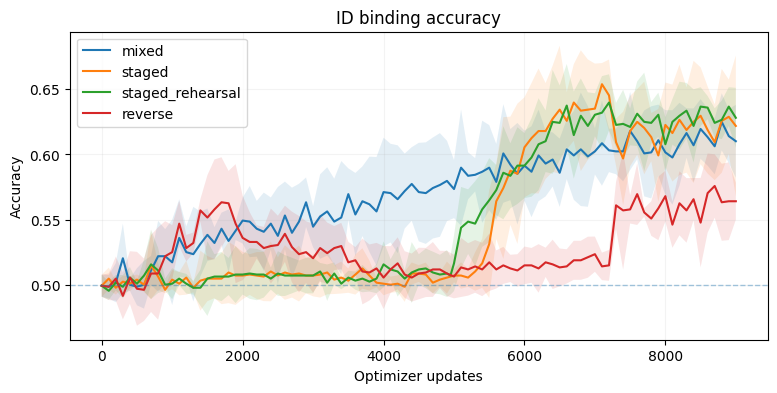

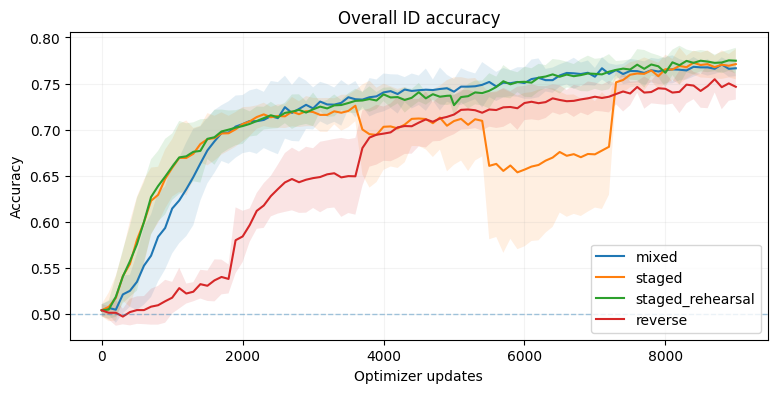

In [7]:
for task, title in (("pair", "ID binding accuracy"), ("overall", "Overall ID accuracy")):
    plt.figure(figsize=(9, 4))
    for schedule in SCHEDULES:
        curves = []
        for run in report["runs"]:
            if run["schedule"] != schedule or run["status"] != "completed":
                continue
            points = {r["step"]: r["id_dev"]["accuracy"] if task == "overall"
                      else r["id_dev"]["by_template"].get("pair", np.nan)
                      for r in run["history"]}
            curves.append(points)
        if not curves:
            continue
        times = sorted(set.intersection(*(set(c) for c in curves)))
        values = np.array([[c[t] for t in times] for c in curves])
        mean = values.mean(axis=0)
        sd = values.std(axis=0, ddof=1) if len(values) > 1 else np.zeros(len(mean))
        plt.plot(times, mean, label=schedule)
        plt.fill_between(times, mean-sd, mean+sd, alpha=0.12)
    plt.axhline(0.5, linestyle="--", linewidth=1, alpha=0.4)
    plt.title(title)
    plt.xlabel("Optimizer updates")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(alpha=0.15)
    plt.show()

**Report:** compare fixed-final ID binding, binding AULC, OOD binding, shape accuracy, and retention before common consolidation. For the 3,000-versus-9,000-step comparison, use `LR_POLICY = "constant"`; the earlier five-seed mixed-reference runs used `1e-4` throughout. Treat cosine decay as a separate optimization experiment.